# Gnod — Evaluating the recommender

**Goal.** Put a number on how good the recommendations are, so the model's
value is proven, not just claimed.

Clustering is *unsupervised* — there is no right/wrong label to score against.
So we use the `genre` column (never used to build the model) as a sensible
stand-in for "a good match": if a recommended song shares the genre of the
song you picked, we count it as a hit.


## Hit rate

For each song we take the 5 recommendations and measure **what share of them
share the genre of the original song**, then average over all songs.

We compare three ways of choosing the 5 songs:

- **random (whole library)** — ignore clusters, pick 5 at random. This is the baseline.
- **random (same cluster)** — pick 5 at random from the song's own cluster.
- **closest (same cluster)** — the app's method: the 5 nearest songs inside the cluster.


In [4]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

df = pd.read_csv("../data/gnod_songs_clustered.csv")

FEATURES = ["danceability", "energy", "loudness", "speechiness", "acousticness",
            "instrumentalness", "liveness", "valence", "tempo"]

# same scaling + distance matrix the app uses
X_scaled = StandardScaler().fit_transform(df[FEATURES])
D = pairwise_distances(X_scaled)

genre = df["genre"].to_numpy()
cluster = df["cluster"].to_numpy()
n = len(df)
print(n, "songs")


1365 songs


In [5]:
K = 5                       # recommendations per song
rng = np.random.default_rng(42)

def hit_rate(mode):
    """Average share of the K recommendations that share the song's genre."""
    hits = total = 0
    for i in range(n):
        same = np.where((cluster == cluster[i]) & (np.arange(n) != i))[0]
        if mode == "random_all":
            pool = np.delete(np.arange(n), i)
            picks = rng.choice(pool, size=min(K, len(pool)), replace=False)
        elif mode == "random_cluster":
            if len(same) == 0:
                continue
            picks = rng.choice(same, size=min(K, len(same)), replace=False)
        else:  # closest_cluster  (what the app does)
            if len(same) == 0:
                continue
            picks = same[np.argsort(D[i, same])][:K]
        total += len(picks)
        hits += int((genre[picks] == genre[i]).sum())
    return hits / total

scores = {
    "random (whole library)": hit_rate("random_all"),
    "random (same cluster)":  hit_rate("random_cluster"),
    "closest (same cluster)": hit_rate("closest_cluster"),
}
results = pd.Series(scores).mul(100).round(1).rename("hit rate %")
results


random (whole library)     8.0
random (same cluster)     22.7
closest (same cluster)    39.2
Name: hit rate %, dtype: float64

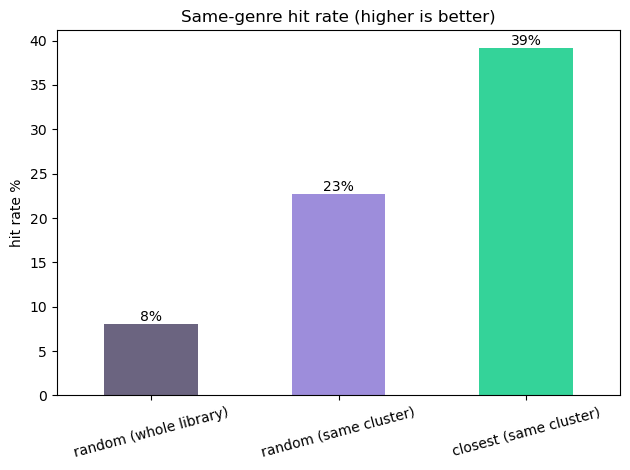

In [6]:
ax = results.plot.bar(color=["#6b6480", "#9d8ddb", "#34d399"], rot=15,
                      title="Same-genre hit rate (higher is better)")
ax.set_ylabel("hit rate %")
ax.bar_label(ax.containers[0], fmt="%.0f%%")
ax.figure.tight_layout()


## What this shows

- Just using clusters already beats random: a same-cluster pick lands a hit
  far more often than a pick from the whole library.
- Taking the **closest** songs in the cluster (the app's method) is the best of
  the three, roughly **5× better than random** across the whole library.

Because the model never saw genre, this is a fair test: grouping songs by how
they *sound* really does put similar songs together. This is the metric that
justifies the recommender — and the choice of `k = 7` clusters.
